In [4]:
import numpy as np
import matplotlib.pyplot as plt
import time

### Problem 1

#### **Part C**

Start the chain at (0, 0) and run T = 5 × 10^4
steps for s = 0.02, 0.5, 5.
Report the acceptance rates and the integrated autocorrelation time of α, and plot the first
400 values of α for each s. For the best s, discard the first 5000 steps, plot the samples of
(α, log β) over contours of the exact posterior computed on a grid, and report the posterior
mean and 90% interval of α and of β from both the chain and the grid. Compare with the
sample mean and sample median of the xi
. Why do s = 0.02 and s = 5 both do badly, in
opposite ways?

Step size = 0.02
Acceptance rate = 0.96314


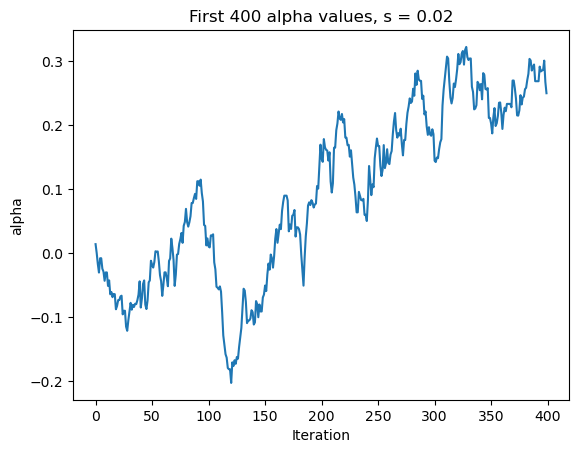

Step size = 0.5
Acceptance rate = 0.36588


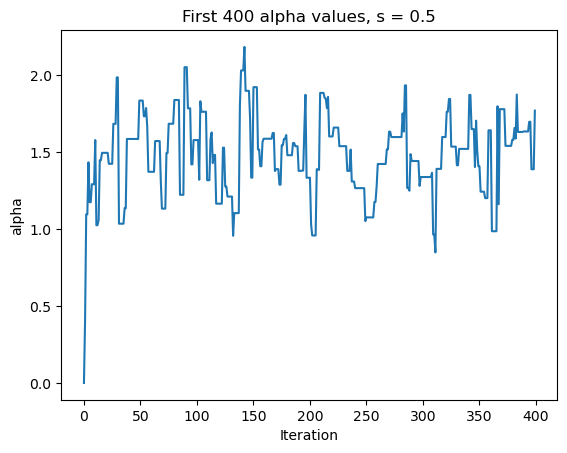

Step size = 5
Acceptance rate = 0.009


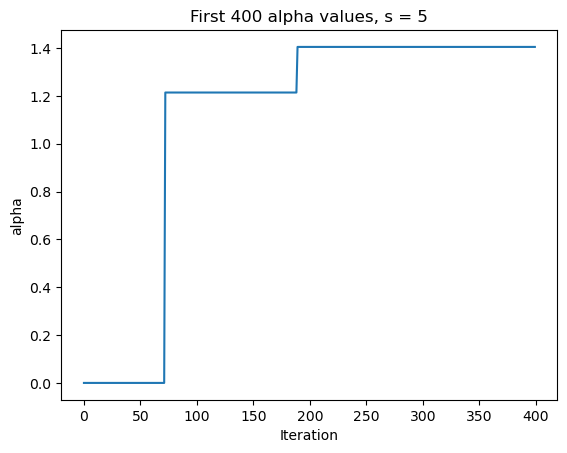

In [76]:
x = np.array([-1.77, 2.47, 1.34, 2.18, 13.05, 1.60, 1.50, -1.97, 0.79, 1.50, 2.00, 2.63, 1.19, -2.31, 0.87])


def log_g(alpha, b):
    return 15*b - np.sum(np.log(np.exp(2*b) + (x-alpha)**2))



def MCMC(start = np.array([0.0, 0.0]), s = 0.02):
    z = start


    samples = np.zeros((5*10**4, 2))
    accepted = 0
    for n in range(5*10**4):
        y = z + s*np.random.randn(2)
        ratio = log_g(y[0], y[1]) - log_g(z[0], z[1])
        
        if np.log(np.random.rand()) < min(0, ratio):
            z = y
            accepted += 1

        samples[n] = z
    
    return samples, accepted/50000

steps = [0.02, 0.5, 5]

for s in steps:
    samples, rate = MCMC(np.array([0.0, 0.0]), s)
    print (f'Step size = {s}')
    print (f'Acceptance rate = {rate}')
    
    plt.figure()
    plt.plot(samples[:400, 0])
    plt.xlabel("Iteration")
    plt.ylabel("alpha")
    plt.title(f"First 400 alpha values, s = {s}")
    plt.show()

In [80]:
samples, rate = MCMC(np.array([0.0, 0.0]), 0.5)
samples = samples[5000:]

alphas = samples[:, 0]
betas = np.exp(samples[:, 1])

print("Mean alpha:", np.mean(alphas))
print("Mean beta:", np.mean(betas))

print("90% interval alpha:", np.percentile(alpha_samples, [5, 95]))
print("90% interval beta:", np.percentile(beta_samples, [5, 95]))

Mean alpha: 1.473359778398771
Mean beta: 0.7742160319590299
90% interval alpha: [1.03621154 1.92235355]
90% interval beta: [0.37209852 1.35474838]


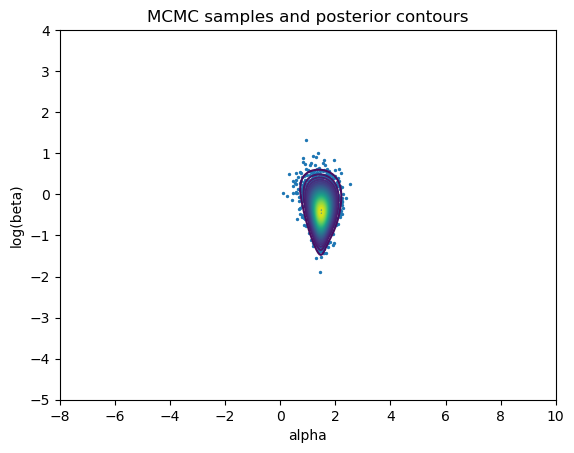

In [100]:
alpha_grid = np.linspace(-8, 10, 400)
b_grid = np.linspace(-5, 4, 400)

A, B = np.meshgrid(alpha_grid, b_grid)
G = np.zeros(A.shape)

for i in range(len(b_grid)):
    for j in range(len(alpha_grid)):
        G[i, j] = log_g(A[i, j], B[i, j])

G = np.exp(G)

plt.contour(A, B, G, levels=30)
plt.scatter(samples[::20, 0], samples[::20, 1], s=2)

plt.xlabel("alpha")
plt.ylabel("log(beta)")
plt.title("MCMC samples and posterior contours")
plt.show()

In [108]:
weights = G / np.sum(G)

grid_mean_alpha = np.sum(A * weights)
grid_mean_beta = np.sum(np.exp(B) * weights)


def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    cumulative = np.cumsum(weights)
    cumulative = cumulative / cumulative[-1]

    return np.interp(q, cumulative, values)


grid_alpha_interval = weighted_quantile( A.ravel(), weights.ravel(), [0.05, 0.95] )

grid_beta_interval = weighted_quantile( np.exp(B).ravel(), weights.ravel(), [0.05, 0.95] )

print("Grid estimates")
print("Mean alpha:", grid_mean_alpha)
print("Mean beta:", grid_mean_beta)
print("90% interval alpha:", grid_alpha_interval)
print("90% interval beta:", grid_beta_interval)


print("\nObserved data")
print("Sample mean:", np.mean(x))
print("Sample median:", np.median(x))


Grid estimates
Mean alpha: 1.482719248253458
Mean beta: 0.7755053772722647
90% interval alpha: [1.02255639 1.92481203]
90% interval beta: [0.37345327 1.38169122]

Observed data
Sample mean: -9.763067518362556
Sample median: 1.5661020835373276


### **Part D**

Draw 2000 data sets of n = 10, 100, 1000 flashes from (α, β) = (1.5, 0.8) and
compute the sample mean and the sample median of each. For each estimator and each n
you then have 2000 estimates. Measure how widely they scatter by the interquartile range
(IQR), the distance between their 25th and 75th percentiles, divided by 1.349; for normally
distributed estimates this equals the standard deviation. We use it because the standard
deviation of a Cauchy sample mean is not defined. Report this scatter for each estimator
and each n. Which estimator improves with n? It is a fact that the mean of n independent
Cauchy variables has exactly the same Cauchy law as a single one. Does your sample mean
settle down as n grows, as the law of large numbers promises? What does that law need
that the Cauchy law lacks? (Hint: try to compute E|X| =
R
|x|f(x) dx.)

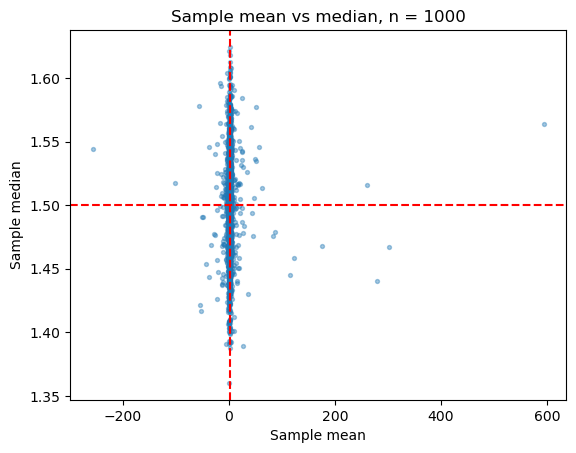

n = 1000
Mean: 1.2038542754599717
Median: 0.03928553014108099



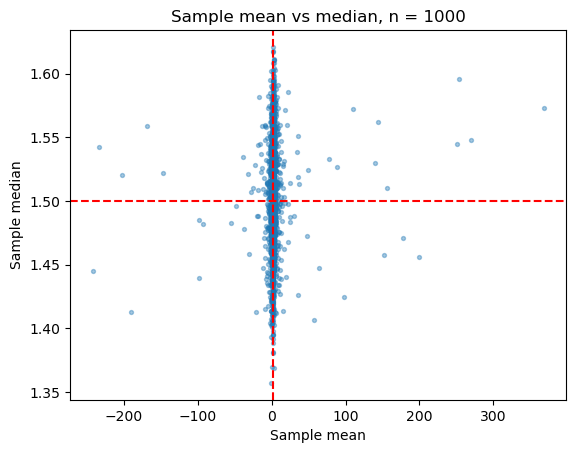

n = 1000
Mean: 1.2821531723732245
Median: 0.03956294139691025



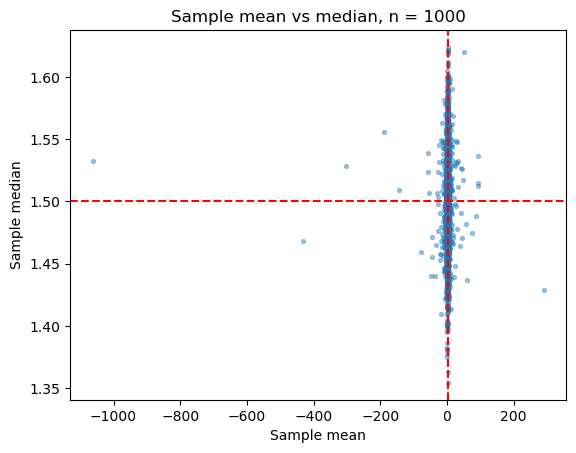

n = 1000
Mean: 1.2852282981876793
Median: 0.03945873318211135



In [120]:
alpha = 1.5
beta = 0.8

R = 2000

Ns = [10, 100, 1000]

for N in Ns:
    means = []
    medians = []

    for i in range(R):
        theta = np.random.uniform(-np.pi/2, np.pi/2, n)
        x = alpha + beta * np.tan(theta)

        means.append(np.mean(x))
        medians.append(np.median(x))

    means = np.array(means)
    medians = np.array(medians)

    plt.scatter(means, medians, s=8, alpha=0.4)

    plt.axhline(alpha, color="red", linestyle="--")
    plt.axvline(alpha, color="red", linestyle="--")

    plt.xlabel("Sample mean")
    plt.ylabel("Sample median")
    plt.title("Sample mean vs median, n = " + str(n))
    plt.show()

    mean_IQR = (np.percentile(means, 75)
                - np.percentile(means, 25))

    median_IQR = (np.percentile(medians, 75)
                  - np.percentile(medians, 25))

    mean_scatter = mean_IQR / 1.349
    median_scatter = median_IQR / 1.349

    print("n =", n)
    print("Mean:", mean_scatter)
    print("Median:", median_scatter)
    print()

## **Problem 2**

Programming. For the six rates above compute E[M] and the probability that each student
is last, by following the group of students still working. With a group still working, the next
finish takes a time with mean 1/(sum of their rates) and is by student i with probability
λi/(sum of their rates), after which the same problem continues with student i removed. Do
this for all 26 groups, starting from all six students. Also compute E[M] from the alternating
formula of (c). Simulate 2 × 105
exams and compare, and plot a histogram of M against
the exact density d
dt
Q
i
(1 − e
−λit
). Check by simulation that the finishing time of the first
student does not depend on who that student is. Then take rates λi = i for k = 1, . . . , 12
students and plot E[M] against k. Does it grow without bound? Show E[M] ≤ 2 ln 2 for
every k, using P(M > t) ≤ min
1,
P
i≥1
e
−it
.

In [127]:
def expected(rates):
    groups = [[]]

    for i in range(len(rates)):
        new_groups = []

        for group in groups:
            new_groups.append(group + [rates[i]])

        groups = groups + new_groups

    exp = 0

    for group in groups:
        if len(group) > 0:
            total = sum(group)

            if len(group) % 2 == 1:
                exp += 1 / total
            else:
                exp -= 1 / total

    return exp


rates = np.array([3, 2, 1.5, 1.2, 1, 0.75])

print("E[M] =", expected(rates))

E[M] = 2.1073764063261615


In [131]:
def prob_last(rates, i):
    others = []
    for j in range(len(rates)):
        if j != i:
            others.append(rates[j])

    groups = [[]]

    for rate in others:
        new_groups = []

        for group in groups:
            new_groups.append(group + [rate])

        groups = groups + new_groups

    prob = 0

    for group in groups:
        total = rates[i] + sum(group)

        if len(group) % 2 == 0:
            prob += rates[i] / total
        else:
            prob -= rates[i] / total

    return prob


rates = np.array([3, 2, 1.5, 1.2, 1, 0.75])

for i in range(6):
    print(f'Student {i + 1} : {prob_last(rates, i)}')


Student 1 : 0.026785553777233684
Student 2 : 0.06953194240859581
Student 3 : 0.12298797892543087
Student 4 : 0.18125241523661045
Student 5 : 0.24098348961223715
Student 6 : 0.35845862003989276


In [139]:
groups = [[]]

for rate in rates:
    new_groups = []

    for group in groups:
        new_groups.append(group + [rate])

    groups = groups + new_groups

for group in groups:
    if len(group) == 0:
        mean = 0
    else:
        mean = expected(group)

    print("Group:", group, "E[M]:", round(mean, 4))

Group: [] E[M]: 0
Group: [3.0] E[M]: 0.3333
Group: [2.0] E[M]: 0.5
Group: [3.0, 2.0] E[M]: 0.6333
Group: [1.5] E[M]: 0.6667
Group: [3.0, 1.5] E[M]: 0.7778
Group: [2.0, 1.5] E[M]: 0.881
Group: [3.0, 2.0, 1.5] E[M]: 0.9459
Group: [1.2] E[M]: 0.8333
Group: [3.0, 1.2] E[M]: 0.9286
Group: [2.0, 1.2] E[M]: 1.0208
Group: [3.0, 2.0, 1.2] E[M]: 1.0774
Group: [1.5, 1.2] E[M]: 1.1296
Group: [3.0, 1.5, 1.2] E[M]: 1.1781
Group: [2.0, 1.5, 1.2] E[M]: 1.2442
Group: [3.0, 2.0, 1.5, 1.2] E[M]: 1.2779
Group: [1.0] E[M]: 1.0
Group: [3.0, 1.0] E[M]: 1.0833
Group: [2.0, 1.0] E[M]: 1.1667
Group: [3.0, 2.0, 1.0] E[M]: 1.2167
Group: [1.5, 1.0] E[M]: 1.2667
Group: [3.0, 1.5, 1.0] E[M]: 1.3096
Group: [2.0, 1.5, 1.0] E[M]: 1.3698
Group: [3.0, 2.0, 1.5, 1.0] E[M]: 1.4
Group: [1.2, 1.0] E[M]: 1.3788
Group: [3.0, 1.2, 1.0] E[M]: 1.4163
Group: [2.0, 1.2, 1.0] E[M]: 1.471
Group: [3.0, 2.0, 1.2, 1.0] E[M]: 1.4977
Group: [1.5, 1.2, 1.0] E[M]: 1.5454
Group: [3.0, 1.5, 1.2, 1.0] E[M]: 1.5687
Group: [2.0, 1.5, 1.2, 1.0] E

In [141]:
Nsim = 200000

times = []
last_students = []
first_times = []
first_students = []

for i in range(Nsim):
    remaining = list(range(6))
    total_time = 0

    while len(remaining) > 0:
        current_rates = []

        for j in remaining:
            current_rates.append(rates[j])

        total_rate = sum(current_rates)

        wait = np.random.exponential(1 / total_rate)
        total_time += wait

        probs = np.array(current_rates) / total_rate
        student = np.random.choice(remaining, p=probs)

        if len(remaining) == 6:
            first_times.append(total_time)
            first_students.append(student)

        remaining.remove(student)

    times.append(total_time)
    last_students.append(student)

times = np.array(times)
last_students = np.array(last_students)
first_times = np.array(first_times)
first_students = np.array(first_students)

In [145]:
print("Simulated E[M]:", np.mean(times))
print("Exact E[M]:", expected(rates))

for i in range(6):
    simulated = np.mean(last_students == i)
    exact = prob_last(rates, i)

    print("Student", i + 1,
          "Simulated:", round(simulated, 4),
          "Exact:", round(exact, 4))

Simulated E[M]: 2.104887047734123
Exact E[M]: 2.1073764063261615
Student 1 Simulated: 0.0275 Exact: 0.0268
Student 2 Simulated: 0.0701 Exact: 0.0695
Student 3 Simulated: 0.1226 Exact: 0.123
Student 4 Simulated: 0.1802 Exact: 0.1813
Student 5 Simulated: 0.2408 Exact: 0.241
Student 6 Simulated: 0.3588 Exact: 0.3585


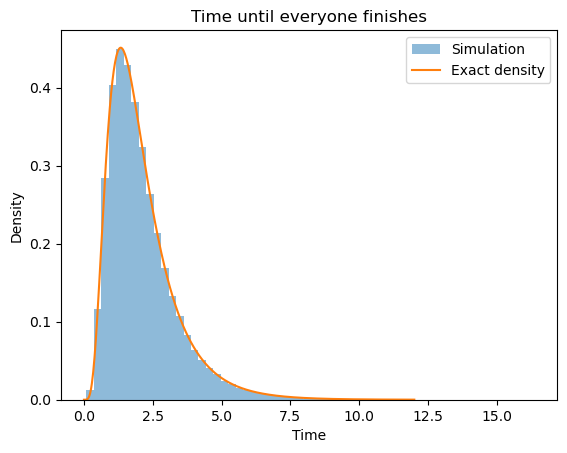

In [147]:
def density_M(t, rates):
    density = 0

    for i in range(len(rates)):
        term = rates[i] * np.exp(-rates[i] * t)

        for j in range(len(rates)):
            if i != j:
                term *= (1 - np.exp(-rates[j] * t))

        density += term

    return density


t = np.linspace(0, 12, 500)

exact = density_M(t, rates)

plt.hist(times, bins=60, density=True, alpha=0.5, label="Simulation")
plt.plot(t, exact, label="Exact density")

plt.xlabel("Time")
plt.ylabel("Density")
plt.title("Time until everyone finishes")
plt.legend()
plt.show()

In [149]:
print("Exact first finishing mean:", 1 / sum(rates))
print("Simulated first finishing mean:", np.mean(first_times))

for i in range(6):
    mean = np.mean(first_times[first_students == i])
    print("Student", i + 1, "first:", round(mean, 4))


Exact first finishing mean: 0.10582010582010583
Simulated first finishing mean: 0.1060798429993657
Student 1 first: 0.1066
Student 2 first: 0.1053
Student 3 first: 0.1061
Student 4 first: 0.1061
Student 5 first: 0.1057
Student 6 first: 0.1067


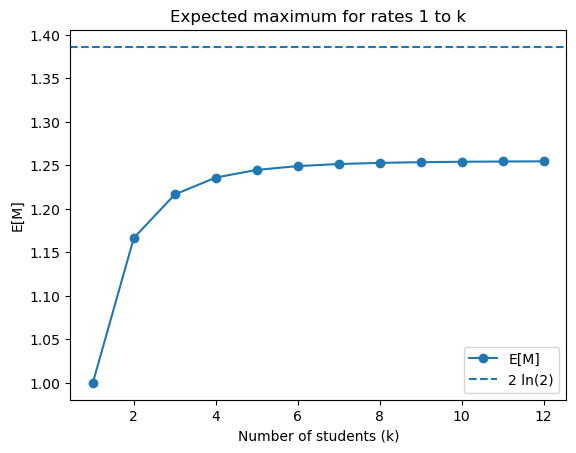

In [153]:
ks = np.arange(1, 13)
means = []

for k in ks:
    new_rates = np.arange(1, k + 1)
    means.append(expected(new_rates))

plt.plot(ks, means, "o-", label="E[M]")
plt.axhline(2 * np.log(2), linestyle="--",label="2 ln(2)")

plt.xlabel("Number of students (k)")
plt.ylabel("E[M]")
plt.title("Expected maximum for rates 1 to k")
plt.legend()
plt.show()

### **Problem 3**

Programming. Simulate 2 × 105 hours of meteors by the exponential gaps, and as many by
the Poisson count plus uniform points. Compare the histograms of N(1) with the Poisson(4)
pmf and report the mean and variance of N(1). Plot ten realizations of each construction
as rasters. Compare the histogram of T3 with its Gamma density. Among the hours with
N(1) = 3, estimate P(N(
1
2
) = 0), E[T1] and the correlation between the counts in the first
and second half hour (over all hours). Finally, compute the total variation distance between
Binomial(t/∆t, λ∆t) and Poisson(λt) for t = 1 and ∆t = 1/10, . . . , 1/2000, and fit its slope
against ∆t on log–log axes.

In [158]:
from scipy.stats import poisson, gamma, binom

lam = 4
Nsim = 200000


counts_exp = []
first_half_exp = []
second_half_exp = []
first_times = []
third_times = []
examples_exp = []

for i in range(Nsim):
    time = 0
    arrivals = []

    while time < 1 or len(arrivals) < 3:
        wait = np.random.exponential(1 / lam)
        time += wait
        arrivals.append(time)

    first = 0
    second = 0

    for t in arrivals:
        if t <= 0.5:
            first += 1
        elif t <= 1:
            second += 1

    counts_exp.append(first + second)
    first_half_exp.append(first)
    second_half_exp.append(second)

    first_times.append(arrivals[0])
    third_times.append(arrivals[2])

    if i < 10:
        examples_exp.append(arrivals)



In [160]:
counts_unif = []
first_half_unif = []
second_half_unif = []
examples_unif = []

for i in range(Nsim):
    n = np.random.poisson(lam)

    arrivals = np.random.uniform(0, 1, n)
    arrivals = np.sort(arrivals)

    first = 0
    second = 0

    for t in arrivals:
        if t <= 0.5:
            first += 1
        else:
            second += 1

    counts_unif.append(n)
    first_half_unif.append(first)
    second_half_unif.append(second)

    if i < 10:
        examples_unif.append(arrivals)

In [162]:
counts_exp = np.array(counts_exp)
counts_unif = np.array(counts_unif)

first_half_exp = np.array(first_half_exp)
second_half_exp = np.array(second_half_exp)

first_half_unif = np.array(first_half_unif)
second_half_unif = np.array(second_half_unif)

first_times = np.array(first_times)
third_times = np.array(third_times)

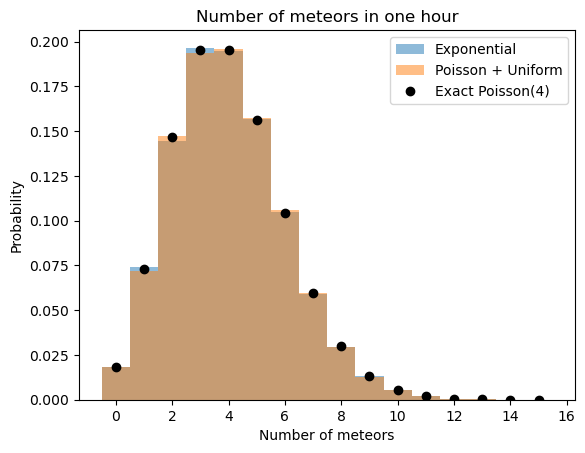

Exponential method:
Mean: 3.99813
Variance: 3.9987465031
Poisson + Uniform method:
Mean: 4.003585
Variance: 3.9748721477750015


In [164]:
k = np.arange(0, 16)

plt.hist(counts_exp, bins=np.arange(-0.5, 16.5, 1), density=True, alpha=0.5, label="Exponential")

plt.hist(counts_unif, bins=np.arange(-0.5, 16.5, 1), density=True, alpha=0.5, label="Poisson + Uniform")

plt.plot(k, poisson.pmf(k, 4), "ko", label="Exact Poisson(4)")

plt.xlabel("Number of meteors")
plt.ylabel("Probability")
plt.title("Number of meteors in one hour")
plt.legend()
plt.show()

print("Exponential method:")
print("Mean:", np.mean(counts_exp))
print("Variance:", np.var(counts_exp))

print("Poisson + Uniform method:")
print("Mean:", np.mean(counts_unif))
print("Variance:", np.var(counts_unif))

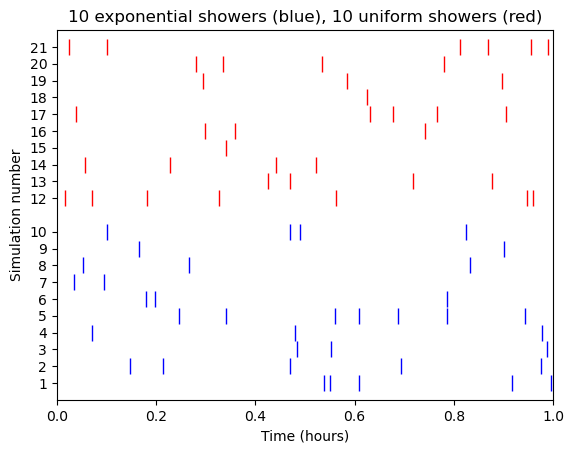

In [166]:
for i in range(10):
    for t in examples_exp[i]:
        if t <= 1:
            plt.plot(t, i + 1, "b|", markersize=12)

    for t in examples_unif[i]:
        plt.plot(t, i + 12, "r|", markersize=12)

plt.xlabel("Time (hours)")
plt.ylabel("Simulation number")
plt.title("10 exponential showers (blue), 10 uniform showers (red)")
plt.xlim(0, 1)
plt.yticks(list(range(1, 11)) + list(range(12, 22)))
plt.show()

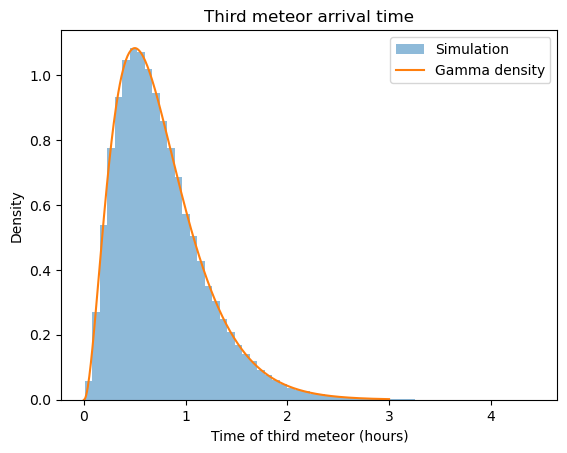

In [170]:
t = np.linspace(0, 3, 400)

plt.hist(third_times, bins=60, density=True, alpha=0.5, label="Simulation")

plt.plot(t, gamma.pdf(t, a=3, scale=1/lam), label="Gamma density")

plt.xlabel("Time of third meteor (hours)")
plt.ylabel("Density")
plt.title("Third meteor arrival time")
plt.legend()
plt.show()

In [172]:
half_counts = first_half_exp[counts_exp == 3]
conditional_first_times = first_times[counts_exp == 3]

print("P(N(1/2) = 0 | N(1) = 3):")
print("Simulation:", np.mean(half_counts == 0))
print("Exact:", 1/8)

print("E[T1 | N(1) = 3]:")
print("Simulation:", np.mean(conditional_first_times))
print("Exact:", 1/4)

P(N(1/2) = 0 | N(1) = 3):
Simulation: 0.12554343680878652
Exact: 0.125
E[T1 | N(1) = 3]:
Simulation: 0.2501481142308126
Exact: 0.25


In [174]:
corr_exp = np.corrcoef(first_half_exp, second_half_exp)[0, 1]
corr_unif = np.corrcoef(first_half_unif, second_half_unif)[0, 1]

print("Exponential correlation:", corr_exp)
print("Uniform correlation:", corr_unif)

Exponential correlation: 9.327287786701905e-05
Uniform correlation: -0.0032964961825678657


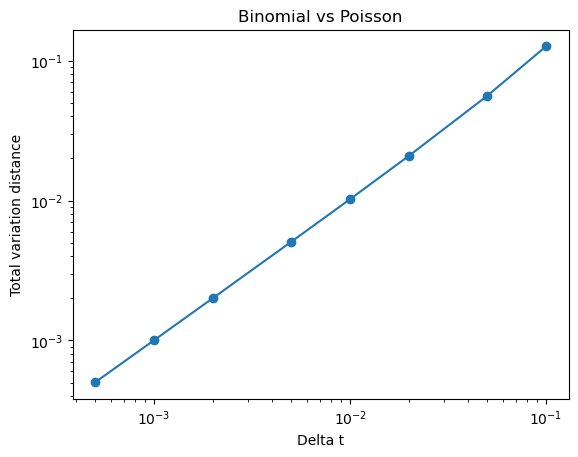

Log-log slope: 1.0359237308411209


In [178]:
dts = np.array([1/10, 1/20, 1/50, 1/100,
                1/200, 1/500, 1/1000, 1/2000])

distances = []

for dt in dts:
    n = round(1 / dt)
    p = lam * dt

    k = np.arange(n + 1)

    b = binom.pmf(k, n, p)
    q = poisson.pmf(k, lam)

    distance = 0.5 * (np.sum(abs(b - q)) + poisson.sf(n, lam))

    distances.append(distance)

distances = np.array(distances)

plt.loglog(dts, distances, "o-")
plt.xlabel("Delta t")
plt.ylabel("Total variation distance")
plt.title("Binomial vs Poisson")
plt.show()

slope, intercept = np.polyfit(np.log(dts),np.log(distances), 1)

print("Log-log slope:", slope)